In [5]:
import scanpy as sc
adata_T = sc.read("../h5ad/adata_T.h5ad")
sc.pp.normalize_total(adata_T, target_sum=1e6)
sc.pp.log1p(adata_T)

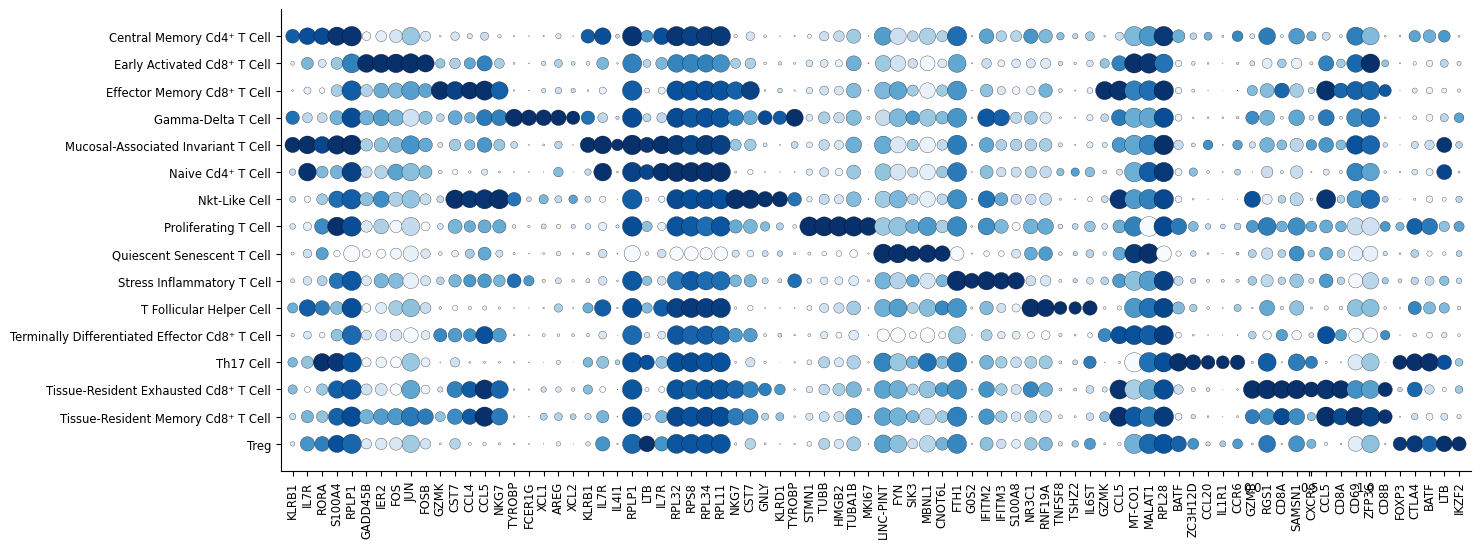

In [11]:
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. Differential expression analysis (find markers)
# ==========================================

plt.rcParams.update({
    # 1. Font settings: specify multiple fallback fonts to prevent boxes when Arial is missing
    'font.family': ['sans-serif'], 
    'font.sans-serif': ['DejaVu Sans']
}) 
sc.tl.rank_genes_groups(adata_T, groupby='celltype', method='wilcoxon')

# ==========================================
# 2. Extract feature genes
# ==========================================
n_genes = 5
markers_to_plot = []

# Get all cell type names (order consistent with rank_genes_groups results)
groups = adata_T.uns['rank_genes_groups']['names'].dtype.names

# Loop through each subgroup and sequentially extract the top n_genes gene names
for group in groups:
    # Extract the top n_genes gene names for the current subgroup
    genes = adata_T.uns['rank_genes_groups']['names'][group][:n_genes]
    markers_to_plot.extend(genes)

# ==========================================
# 3. Plot dot plot (remove default legend)
# ==========================================
# 1. Draw the plot first, set show=False so we can modify it afterwards
sc.pl.dotplot(
    adata_T, 
    markers_to_plot, 
    groupby='celltype', 
    dendrogram=False,     
    standard_scale='var', 
    figsize=(14, 6),
    cmap="Blues",
    show=False 
)

# 2. Get the current Figure object
fig = plt.gcf()

# 3. Identify and remove the two default legend axes on the right (color bar and bubble size)
axes_to_remove = []
for ax in fig.axes:
    # Check if the Y-axis label contains legend keywords
    label = ax.get_ylabel()
    if "expression" in label or "cells in group" in label:
        axes_to_remove.append(ax)

# Execute removal
for ax in axes_to_remove:
    ax.remove()

# 4. Readjust the width of the main plot to fill the blank left after removing the legend
# Get the main plot axis (usually the first one remaining)
main_ax = fig.axes[0]
# Get the current position [left, bottom, width, height]
pos = main_ax.get_position()
# Extend the width to the right (for example, extend to 0.9)
main_ax.set_position([pos.x0, pos.y0, 0.85, pos.height])

# 5. Remove the top and right spines
sns.despine(fig=fig, top=True, right=True)

# 6. Display the final result
plt.show()

In [13]:
adata_B = sc.read("../h5ad/adata_B.h5ad")
sc.pp.normalize_total(adata_B, target_sum=1e6)
sc.pp.log1p(adata_B)

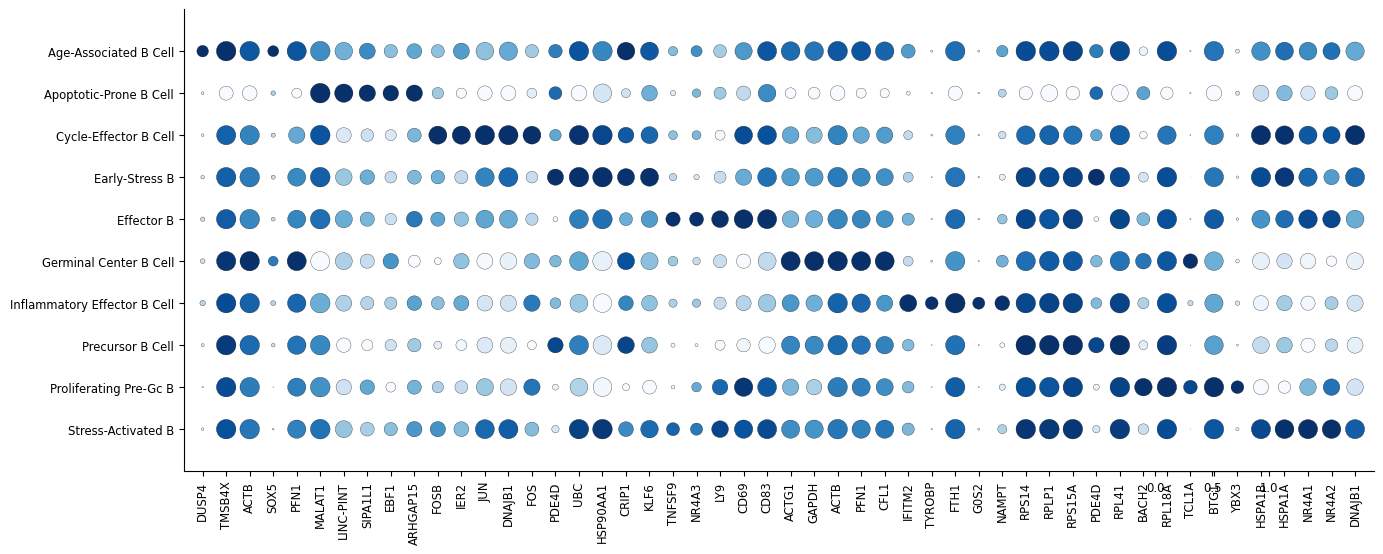

In [17]:
import scanpy as sc
import matplotlib.pyplot as plt

# ==========================================
# 1. Differential expression analysis (find markers)
# ==========================================
sc.tl.rank_genes_groups(adata_B, groupby='celltype', method='wilcoxon')

# ==========================================
# 2. Extract feature genes
# ==========================================
n_genes = 5
markers_to_plot = []

# Get all cell type names (order consistent with rank_genes_groups results)
groups = adata_B.uns['rank_genes_groups']['names'].dtype.names

# Loop through each subgroup and sequentially extract the top n_genes gene names
for group in groups:
    # Extract the top n_genes gene names for the current subgroup
    genes = adata_B.uns['rank_genes_groups']['names'][group][:n_genes]
    markers_to_plot.extend(genes)

# ==========================================
# 3. Plot dot plot (remove default legend)
# ==========================================
# 1. Draw the plot first, set show=False so we can modify it afterwards
sc.pl.dotplot(
    adata_B, 
    markers_to_plot, 
    groupby='celltype', 
    dendrogram=False,     
    standard_scale='var', 
    figsize=(14, 6),
    cmap="Blues",
    show=False  
)

# 2. Get the current Figure object
fig = plt.gcf()

# 3. Identify and remove the two default legend axes on the right (color bar and bubble size)
axes_to_remove = []
for ax in fig.axes:
    # Check if the Y-axis label contains legend keywords
    label = ax.get_ylabel()
    if "expression" in label or "cells in group" in label:
        axes_to_remove.append(ax)

# Execute removal
for ax in axes_to_remove:
    ax.remove()

# 4. Readjust the width of the main plot to fill the blank left after removing the legend
# Get the main plot axis (usually the first one remaining)
main_ax = fig.axes[0]
# Get the current position [left, bottom, width, height]
pos = main_ax.get_position()
# Extend the width to the right (for example, extend to 0.9)
main_ax.set_position([pos.x0, pos.y0, 0.85, pos.height])

# 5. Remove the top and right spines
sns.despine(fig=fig, top=True, right=True)

# 6. Display the final result
plt.show()

In [18]:
adata_myeloid = sc.read("../h5ad/adata_myeloid.h5ad")
sc.pp.normalize_total(adata_myeloid, target_sum=1e6)
sc.pp.log1p(adata_myeloid)

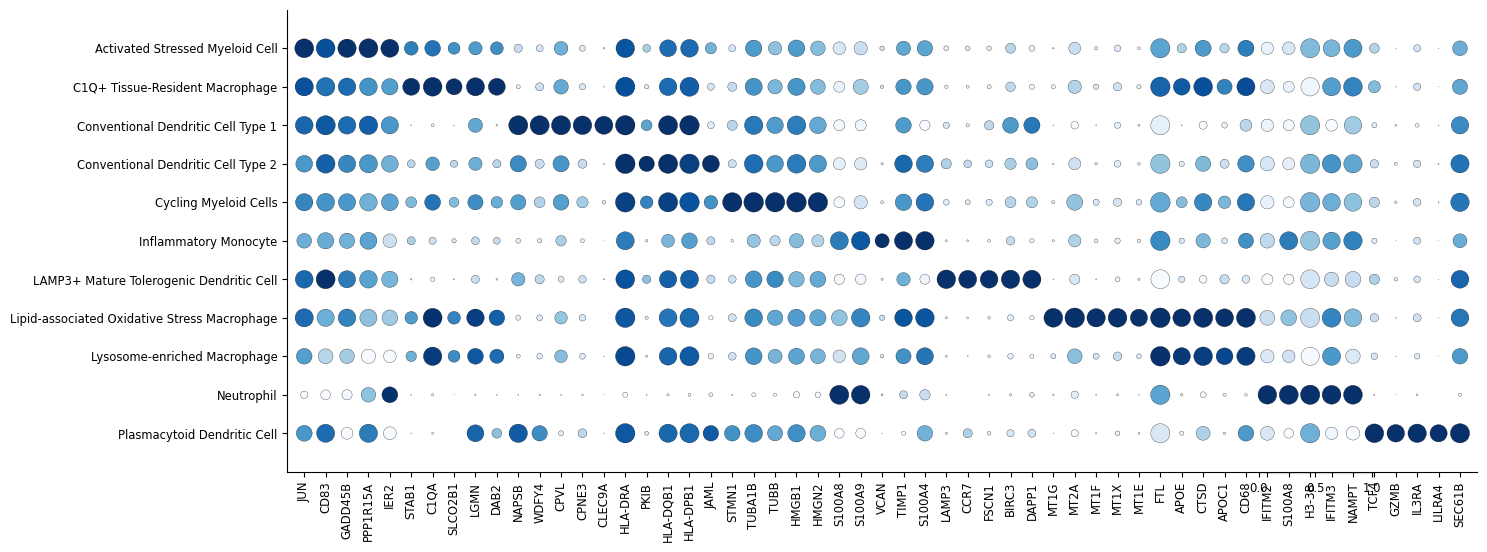

In [19]:
import scanpy as sc
import matplotlib.pyplot as plt

# ==========================================
# 1. Differential expression analysis (find markers)
# ==========================================
sc.tl.rank_genes_groups(adata_myeloid, groupby='celltype', method='wilcoxon')

# ==========================================
# 2. Extract feature genes (skip ENSG IDs)
# ==========================================
n_genes = 5
markers_to_plot = []

# Get all cell type names (order consistent with rank_genes_groups results)
groups = adata_myeloid.uns['rank_genes_groups']['names'].dtype.names

# Loop through each subgroup and sequentially extract the top n_genes valid genes
for group in groups:
    # Get all gene names for the current subgroup (ranked from highest to lowest differential expression)
    all_genes = adata_myeloid.uns['rank_genes_groups']['names'][group]
    
    valid_genes = []
    for gene in all_genes:
        # If the gene name starts with ENSG, skip it directly
        if gene.startswith("ENSG"):
            continue
        valid_genes.append(gene)
        # Stop once n_genes valid genes are collected
        if len(valid_genes) == n_genes:
            break
            
    markers_to_plot.extend(valid_genes)

# ==========================================
# 3. Plot dot plot (remove default legend)
# ==========================================
# 1. Draw the plot first, set show=False so we can modify it afterwards
sc.pl.dotplot(
    adata_myeloid, 
    markers_to_plot, 
    groupby='celltype', 
    dendrogram=False,     
    standard_scale='var', 
    figsize=(14, 6),
    cmap="Blues",
    show=False  
)

# 2. Get the current Figure object
fig = plt.gcf()

# 3. Identify and remove the two default legend axes on the right (color bar and bubble size)
axes_to_remove = []
for ax in fig.axes:
    # Check if the Y-axis label contains legend keywords
    label = ax.get_ylabel()
    if "expression" in label or "cells in group" in label:
        axes_to_remove.append(ax)

# Execute removal
for ax in axes_to_remove:
    ax.remove()

# 4. Readjust the width of the main plot to fill the blank left after removing the legend
# Get the main plot axis (usually the first one remaining)
main_ax = fig.axes[0]
# Get the current position [left, bottom, width, height]
pos = main_ax.get_position()
# Extend the width to the right (for example, extend to 0.9)
main_ax.set_position([pos.x0, pos.y0, 0.85, pos.height])

# 5. Remove the top and right spines
sns.despine(fig=fig, top=True, right=True)

# 6. Display the final result
plt.show()